# Chapter 1 · Probability as information: interactive demos

Companion to Chapter 1 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/01-probability.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Everything in sections 1 to 3 is **exact**: the $2^n$ outcomes of $n$ coin tosses are enumerated, and
expectations are finite sums. Only the Gaussian part of section 3 uses random samples.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

from math import comb
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from ieor222.cointoss import (coin_density, conditional_expectation, effective_sample_size,
                              expectation, gaussian_shift_sample, least_squares, outcome_names,
                              partition_of, stock_prices, toss_partition, toss_probabilities,
                              toss_space)
from ieor222.style import COBALT, GOLD, GREY, INK, use_style

use_style()
S0, U, D = 4.0, 1.5, 0.5          # the stock of the notes: S_k = S0 u^(heads) d^(tails)

## 1. Conditional expectation on the coin-toss tree

On the $n$-toss space, the information $\mathcal F_k$ of the first $k$ tosses is a partition into $2^k$ atoms:
the nodes at depth $k$ of the binary tree. Given $\mathcal F_k$, the conditional expectation of a payoff $X$ is,
on each atom, the probability-weighted average of $X$ over that atom.

Left: the tree, with each node labelled by $E[X\mid\mathcal F_k]$ on the corresponding atom (the leaves carry $X$ itself).
Right: the same numbers as step functions over the outcomes, each outcome drawn with width equal to its probability.
The printout checks the tower property $E\big[E[X\mid\mathcal F_j]\mid\mathcal F_k\big]=E[X\mid\mathcal F_k]$ for all $k\le j$.

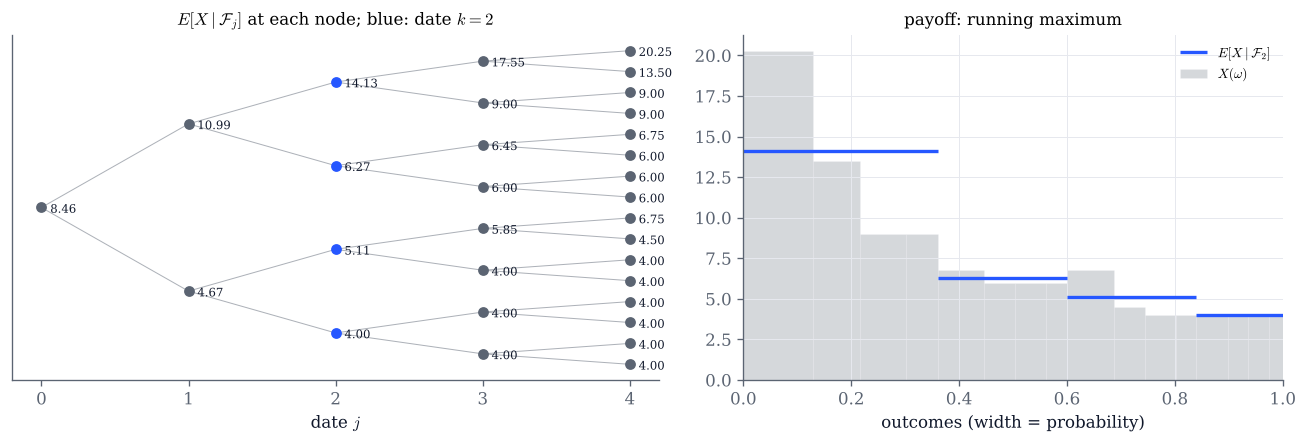

E[X] = 8.4580;  largest violation of the tower property: 3.6e-15


In [2]:
PAYOFFS = {
    "stock S_n": lambda S, H: S[:, -1],
    "call (S_n - S_0)^+": lambda S, H: np.maximum(S[:, -1] - S0, 0.0),
    "running maximum": lambda S, H: S.max(axis=1),
    "number of heads": lambda S, H: H.sum(axis=1).astype(float),
}

def tree(n=4, p=0.6, k=2, payoff="running maximum"):
    k = min(k, n)
    heads = toss_space(n)
    prob = toss_probabilities(heads, p)
    S = stock_prices(heads, S0, U, D)
    X = PAYOFFS[payoff](S, heads)
    levels = [conditional_expectation(X, prob, toss_partition(n, j)) for j in range(n + 1)]

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
    # the tree: node i at depth j sits above the middle of the outcomes it contains
    for j in range(n + 1):
        for i in range(2**j):
            y = (i + 0.5) * 2 ** (n - j) - 0.5
            val = levels[j][i * 2 ** (n - j)]
            if j < n:
                for c in (2 * i, 2 * i + 1):
                    ax.plot([j, j + 1], [y, (c + 0.5) * 2 ** (n - j - 1) - 0.5], color=GREY, lw=0.6, alpha=0.5)
            ax.scatter(j, y, s=30 if n <= 5 else 10, color=COBALT if j == k else GREY, zorder=3)
            if n <= 4:
                ax.text(j + 0.06, y + 0.25, f"{val:.2f}", fontsize=7, color=INK)
    ax.invert_yaxis()
    ax.set(xlabel="date $j$", xticks=range(n + 1), yticks=[],
           title=f"$E[X\\mid\\mathcal{{F}}_j]$ at each node; blue: date $k={k}$")
    ax.grid(False)

    edges = np.concatenate([[0.0], np.cumsum(prob)])
    ax2.bar(edges[:-1], X, width=prob, align="edge", color=GREY, alpha=0.25, edgecolor="white",
            linewidth=0.4, label="$X(\\omega)$")
    lab = toss_partition(n, k)
    for a in np.unique(lab):
        idx = np.flatnonzero(lab == a)
        ax2.hlines(levels[k][idx[0]], edges[idx[0]], edges[idx[-1] + 1], color=COBALT, lw=2,
                   label=f"$E[X\\mid\\mathcal{{F}}_{k}]$" if a == 0 else None)
    ax2.set(xlim=(0, 1), xlabel="outcomes (width = probability)", title=f"payoff: {payoff}")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    err = max(np.abs(conditional_expectation(levels[j], prob, toss_partition(n, i)) - levels[i]).max()
              for i in range(n + 1) for j in range(i, n + 1))
    print(f"E[X] = {expectation(X, prob):.4f};  largest violation of the tower property: {err:.1e}")

tree()

In [3]:
# Explore: change the bias of the coin, the number of tosses, the date k and the payoff.
interact(tree,
         n=IntSlider(value=4, min=1, max=8, continuous_update=False, description="n"),
         p=FloatSlider(value=0.6, min=0.05, max=0.95, step=0.05, continuous_update=False, description="p"),
         k=IntSlider(value=2, min=0, max=8, continuous_update=False, description="k"),
         payoff=Dropdown(options=list(PAYOFFS), value="running maximum", description="payoff"));

## 2. Conditional expectation as the best predictor

$E[X\mid S_k]$ is the orthogonal projection of $X$ onto the functions of $S_k$: among all predictors $h(S_k)$ it has the
smallest mean squared error. Linear regression projects onto a smaller space (affine functions of $S_k$), polynomial
regression of degree $m$ onto polynomials of degree $m$. Since $S_k$ takes only $k+1$ values, polynomials of degree
$k$ already include every function of $S_k$, and the polynomial fit then coincides with $E[X\mid S_k]$.

Below, $X=(S_n-K)^+$ is a call payoff, in a model with $S_0=100$, $u=1.15$, $d=1/u$. Grey dots show the conditional law of
$X$ given each value of $S_k$ (area proportional to probability).

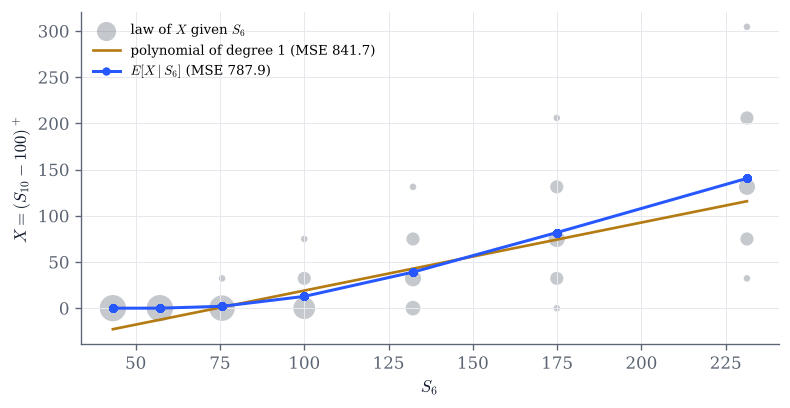

S_6 takes 7 values; MSE of the fit minus MSE of E[X|S_k] = 53.709 = E[(E[X|S_k] - fit)^2] = 53.709


In [4]:
def regression(n=10, k=6, degree=1, K=100.0, p=0.5):
    k = min(k, n)
    heads = toss_space(n)
    prob = toss_probabilities(heads, p)
    S = stock_prices(heads, 100.0, 1.15, 1 / 1.15)
    X = np.maximum(S[:, n] - K, 0.0)
    ce = conditional_expectation(X, prob, partition_of(S[:, k]))
    fit = least_squares(X, np.vander(S[:, k] / 100.0, degree + 1), prob)
    mse = lambda Y: expectation((X - Y) ** 2, prob)

    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    pts = {}
    for i in range(len(X)):
        key = (round(S[i, k], 8), round(X[i], 8))
        pts[key] = pts.get(key, 0.0) + prob[i]
    mass = {}
    for (s, _), m in pts.items():
        mass[s] = mass.get(s, 0.0) + m
    xs, ys, sz = zip(*[(s, x, m / mass[s]) for (s, x), m in pts.items()])
    ax.scatter(xs, ys, s=250 * np.array(sz), color=GREY, alpha=0.35, lw=0, label=f"law of $X$ given $S_{k}$")
    order = np.argsort(S[:, k])
    grid = np.linspace(S[:, k].min(), S[:, k].max(), 300)
    coef = np.linalg.lstsq(np.vander(S[:, k] / 100.0, degree + 1) * np.sqrt(prob)[:, None],
                           X * np.sqrt(prob), rcond=None)[0]
    ax.plot(grid, np.vander(grid / 100.0, degree + 1) @ coef, color=GOLD, lw=1.6,
            label=f"polynomial of degree {degree} (MSE {mse(fit):.1f})")
    ax.plot(S[order, k], ce[order], color=COBALT, lw=1.8, marker="o", ms=4,
            label=f"$E[X\\mid S_{k}]$ (MSE {mse(ce):.1f})")
    ax.set(xlabel=f"$S_{k}$", ylabel=f"$X=(S_{{{n}}}-{K:g})^+$")
    ax.legend(fontsize=8, loc="upper left")
    plt.show()
    print(f"S_{k} takes {k + 1} values; MSE of the fit minus MSE of E[X|S_k] = "
          f"{mse(fit) - mse(ce):.3f} = E[(E[X|S_k] - fit)^2] = {expectation((ce - fit) ** 2, prob):.3f}")

regression()

In [5]:
# Explore: raise the degree until the gold curve passes through every blue dot.
interact(regression,
         n=IntSlider(value=10, min=2, max=14, continuous_update=False, description="n"),
         k=IntSlider(value=6, min=1, max=14, continuous_update=False, description="k"),
         degree=IntSlider(value=1, min=0, max=10, continuous_update=False, description="degree"),
         K=FloatSlider(value=100, min=50, max=200, step=5, continuous_update=False, description="K"),
         p=FloatSlider(value=0.5, min=0.05, max=0.95, step=0.05, continuous_update=False, description="p"));

## 3. Changing the measure by reweighting

**Coins.** Let $\mathbb P$ be the $p$-coin and $\mathbb Q$ the $\tilde p$-coin on $n$ tosses. Every outcome keeps its place;
only its weight changes, by the factor $Z=d\mathbb Q/d\mathbb P=(\tilde p/p)^{H_n}(\tilde q/q)^{n-H_n}$. Left: the law of the
number of heads under $\mathbb P$, under $\mathbb Q$, and under $\mathbb P$ reweighted by $Z$, which is exactly $\mathbb Q$.
Right: the weight as a function of the number of heads.

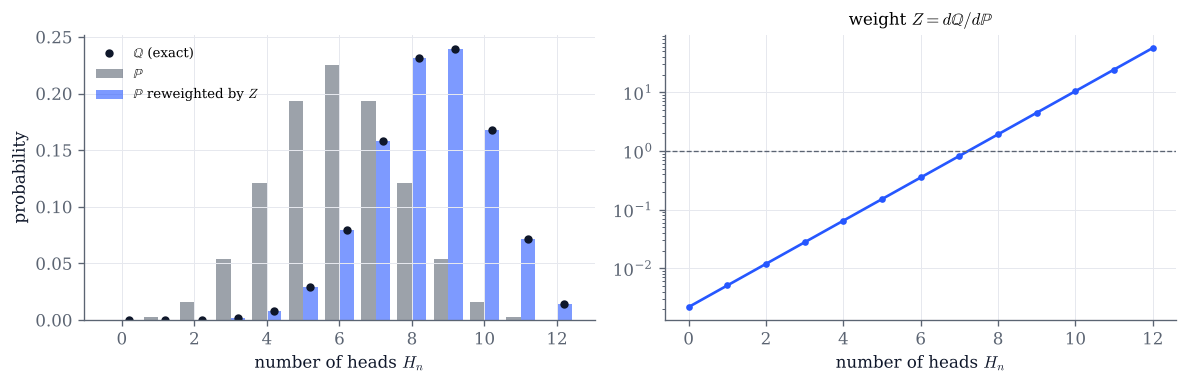

E[Z] = 1.000000;  largest |Z P - Q| over the 4096 outcomes: 0.0e+00


In [6]:
def coins(n=12, p=0.5, p_tilde=0.7):
    heads = toss_space(n)
    P = toss_probabilities(heads, p)
    Z = coin_density(heads, p, p_tilde)
    h = heads.sum(axis=1)
    j = np.arange(n + 1)
    lawP = np.array([P[h == i].sum() for i in j])
    lawQ = np.array([comb(n, i) * p_tilde**i * (1 - p_tilde) ** (n - i) for i in j])
    lawZ = np.array([(Z * P)[h == i].sum() for i in j])
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.3))
    ax.bar(j - 0.2, lawP, width=0.4, color=GREY, alpha=0.6, label="$\\mathbb{P}$")
    ax.bar(j + 0.2, lawZ, width=0.4, color=COBALT, alpha=0.6, label="$\\mathbb{P}$ reweighted by $Z$")
    ax.plot(j + 0.2, lawQ, "o", color=INK, ms=4, label="$\\mathbb{Q}$ (exact)")
    ax.set(xlabel="number of heads $H_n$", ylabel="probability")
    ax.legend(fontsize=8)
    ax2.semilogy(j, (p_tilde / p) ** j * ((1 - p_tilde) / (1 - p)) ** (n - j), color=COBALT, marker="o", ms=3)
    ax2.axhline(1.0, color=GREY, ls="--", lw=0.8)
    ax2.set(xlabel="number of heads $H_n$", title="weight $Z = d\\mathbb{Q}/d\\mathbb{P}$")
    fig.tight_layout()
    plt.show()
    print(f"E[Z] = {expectation(Z, P):.6f};  largest |Z P - Q| over the {2**n} outcomes: "
          f"{np.abs(Z * P - toss_probabilities(heads, p_tilde)).max():.1e}")

coins()

In [7]:
interact(coins,
         n=IntSlider(value=12, min=1, max=16, continuous_update=False, description="n"),
         p=FloatSlider(value=0.5, min=0.05, max=0.95, step=0.05, continuous_update=False, description="p"),
         p_tilde=FloatSlider(value=0.7, min=0.05, max=0.95, step=0.05, continuous_update=False, description="p̃"));

**The Gaussian shift.** Draw $X_1,\dots,X_N$ from $\mathcal N(0,1)$ and give sample $i$ the weight
$Z_i=e^{\theta X_i-\theta^2/2}$. The weighted histogram follows the $\mathcal N(\theta,1)$ density: the measure
$d\mathbb Q=Z\,d\mathbb P$ shifts the mean without changing the shape. The price is paid in the weights: their second moment
is $E[Z^2]=e^{\theta^2}$, and the *effective sample size* $(\sum Z_i)^2/\sum Z_i^2$ is roughly $N e^{-\theta^2}$.

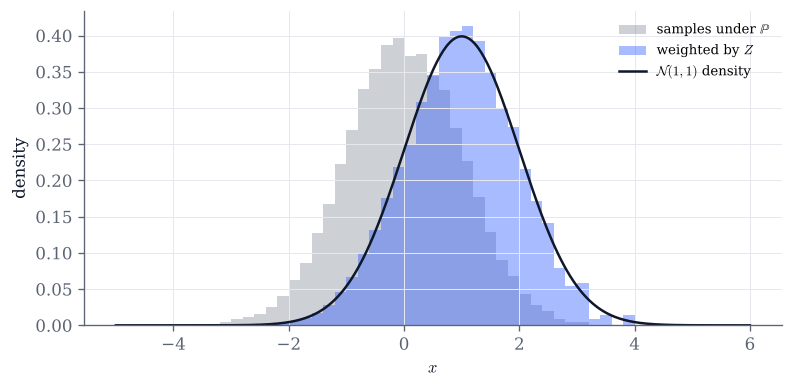

weighted mean +0.983 (target +1.000), weighted variance 0.959 (target 1)
effective sample size 7,694 of 20,000; N e^(-theta^2) = 7,358


In [8]:
def gaussian(theta=1.0, n_samples=20_000, seed=0):
    X, Z = gaussian_shift_sample(theta, n_samples, seed=seed)
    grid = np.linspace(-5, 6, 400)
    phi = lambda x: np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)
    bins = np.linspace(-5, 6, 56)
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.hist(X, bins=bins, density=True, color=GREY, alpha=0.3, label="samples under $\\mathbb{P}$")
    ax.hist(X, bins=bins, weights=Z, density=True, color=COBALT, alpha=0.4, label="weighted by $Z$")
    ax.plot(grid, phi(grid - theta), color=INK, lw=1.5, label=f"$\\mathcal{{N}}({theta:g},1)$ density")
    ax.set(xlabel="$x$", ylabel="density")
    ax.legend(fontsize=8)
    plt.show()
    w = Z / Z.sum()
    print(f"weighted mean {np.sum(w * X):+.3f} (target {theta:+.3f}), weighted variance "
          f"{np.sum(w * (X - np.sum(w * X)) ** 2):.3f} (target 1)")
    print(f"effective sample size {effective_sample_size(Z):,.0f} of {n_samples:,}; "
          f"N e^(-theta^2) = {n_samples * np.exp(-theta**2):,.0f}")

gaussian()

In [9]:
# Explore: how far can you shift before the weights degenerate?
interact(gaussian,
         theta=FloatSlider(value=1.0, min=-3.0, max=3.0, step=0.1, continuous_update=False, description="θ"),
         n_samples=IntSlider(value=20_000, min=1_000, max=200_000, step=1_000, continuous_update=False, description="samples"),
         seed=IntSlider(value=0, min=0, max=100, continuous_update=False, description="seed"));

## Things to try

- In section 1, take the payoff $S_n$ and $p=\frac12$, so that $pu+qd=1$. What do you notice about the node values? Now take
  $p=0.6$: by what factor does the value grow from one date to the next?
- In section 1, with the running maximum and $n=4$, compare the values at the nodes $HT$ and $TH$ at date 2. The price is the
  same at both nodes; why are the forecasts different?
- In section 2, find the smallest degree at which the gold curve passes through every blue dot. Does it depend on $n$? On $k$?
- In section 3, set $\tilde p$ far from $p$ with $n=16$. Which outcomes receive enormous weights, and how likely are they under $\mathbb P$?
- In section 3, increase $|\theta|$ until the weighted histogram becomes ragged, and compare the effective sample size with $Ne^{-\theta^2}$.